# WattRota — Fiyat tahmininin üretim kararına etkisi

## 1. Araştırma sorusu

**Daha düşük fiyat tahmin hatası, aynı üretim işleri için daha düşük gerçekleşmiş maliyet sağlıyor mu?**

Karar 5 Ekim 2026 saat 00.00'da verilir; plan 5–7 Ekim'i kapsar. İlk günün fiyatı açıklanmış kabul edilir. Sonraki iki gün için üç bilgi koşulu karşılaştırılır:

- Üç günün tüm fiyatlarının bilindiği kıyas.
- Açıklanmış ilk gün + 2025 doğrulamasında seçilen basit yöntemle 48 saat tahmin.
- Açıklanmış ilk gün + 2025 doğrulamasında seçilen Random Forest ile 48 saat tahmin.

Firmanın kaynakları, sipariş miktarları, stok hedefleri ve göreli bakım/teslim takvimi aynı tutulur. Tahminli planlar oluşturulduktan sonra gerçekleşmiş fiyatlarla yeniden fiyatlandırılır. Beklenen maliyet ile gerçekleşmiş maliyet birbirine karıştırılmaz.

Her arama aynı 120 saniyelik ana süre sınırını ve %0,1 hedef göreli açığı kullanır; ön aramada en fazla dört 10 saniyelik alt problem vardır. Tüm fiyatların bilindiği kıyas da süre sınırlıdır ve matematiksel optimum sayılmaz. Tahminli bir plan kıyastan daha iyi görünürse bu, çözücü aramasının etkisini de içerebilir.

In [1]:
from pathlib import Path
import sys
import copy
import json
import hashlib
from zipfile import ZipFile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

proje = Path.cwd()
if not (proje / "src").is_dir():
    proje = proje.parent
sys.path.insert(0, str(proje / "src"))
from firma_cizelgeleme import maliyet_ve_ozet
from tahminli_cizelgeleme import karar_firmasini_hazirla, planlama_fiyatlarini_hazirla, YONTEMLER

folder = proje / "data/results/tahminli_cizelgeleme"
tahmin_folder = proje / "data/results/fiyat_tahmini"
tahminler = pd.read_csv(tahmin_folder / "saatlik_tahminler.csv", parse_dates=["karar_zamani", "tarih_saat"])
gercek_firma = karar_firmasini_hazirla(proje)
referans_ozet = maliyet_ve_ozet(gercek_firma, gercek_firma["referans_plan"], gercek_firma["referans_yuklemeler"])[-1]
etiketler = {"tum_fiyatlar_biliniyor": "Tüm fiyatlar biliniyor",
             "basit_tahmin": "Basit tahmin", "ml_tahmin": "Makine öğrenmesi"}

## 2. Aynı girdi ve bağımsız maliyet kontrolü

Her sonuç dosyasındaki kaynak izleri doğrulanır. Kullanılmış gerçek firma girdileri arşivden yeniden okunur ve aynı firmaya ait oldukları kontrol edilir. Her öneri kendi planlama fiyatlarıyla ve gerçekleşmiş fiyatlarla ayrı ayrı hesaplanır. Fiziksel koşullar iki fiyatlandırmada da aynıdır.

In [2]:
satirlar = []
raporlar = {}
sonuclar = {}
for yontem in YONTEMLER:
    klasor = folder / yontem
    bilgi = json.loads((klasor / "sonuc.json").read_text(encoding="utf-8"))
    for ad, beklenen in bilgi["kaynak_sha256"].items():
        assert hashlib.sha256((proje / ad).read_bytes()).hexdigest() == beklenen, ad
    if "tahmin_sha256" in bilgi:
        assert hashlib.sha256((tahmin_folder / "saatlik_tahminler.csv").read_bytes()).hexdigest() == bilgi["tahmin_sha256"]
    with ZipFile(klasor / "gercek_firma_girdileri.zip") as z:
        for ad, beklenen in gercek_firma.items():
            with z.open(ad + ".csv") as dosya:
                kayit = pd.read_csv(dosya, encoding="utf-8-sig", keep_default_na=False)
            for alan in beklenen.columns:
                if pd.api.types.is_datetime64_any_dtype(beklenen[alan]):
                    kayit[alan] = pd.to_datetime(kayit[alan])
            pd.testing.assert_frame_equal(kayit, beklenen.reset_index(drop=True), check_dtype=False)
    fiyat, rapor = planlama_fiyatlarini_hazirla(gercek_firma["fiyatlar"], yontem, tahminler, bilgi["model"])
    kayitli_rapor = pd.read_csv(klasor / "planlama_fiyatlari.csv", parse_dates=["tarih_saat"])
    pd.testing.assert_frame_equal(rapor, kayitli_rapor, check_dtype=False)
    plan = pd.read_csv(klasor / "onerilen_plan.csv", keep_default_na=False)
    yuk = pd.read_csv(klasor / "onerilen_yuklemeler.csv")
    plan["tarih_saat"] = pd.to_datetime(plan["tarih_saat"])
    yuk["tarih_saat"] = pd.to_datetime(yuk["tarih_saat"])
    planlama_firmasi = copy.deepcopy(gercek_firma)
    planlama_firmasi["fiyatlar"] = fiyat
    beklenen = maliyet_ve_ozet(planlama_firmasi, plan, yuk)[-1]
    gerceklesen = maliyet_ve_ozet(gercek_firma, plan, yuk)[-1]
    assert np.isclose(beklenen.iloc[-1], bilgi["planlama_maliyeti_tl"], atol=0.02, rtol=0)
    assert np.isclose(gerceklesen.iloc[-1], bilgi["gerceklesen_maliyet_tl"], atol=0.02, rtol=0)
    assert np.isclose(beklenen.iloc[-1], bilgi["cozum"]["maliyet_tl"], atol=0.02, rtol=0)
    satirlar.append([etiketler[yontem], bilgi["model"], bilgi["fiyat_MAE_TL_MWh"],
                    beklenen.iloc[-1], gerceklesen.iloc[-1], bilgi["gerceklesen_avantaj_tl"],
                    bilgi["gerceklesen_avantaj_yuzde"], bilgi["degisen_uretim_kaynak_saat"],
                    100*bilgi["cozum"]["goreli_acik"], bilgi["cozum"]["durum"]])
    raporlar[yontem] = rapor
    sonuclar[yontem] = bilgi
karsilastirma = pd.DataFrame(satirlar, columns=["Yöntem", "Fiyat modeli", "48 saat fiyat MAE (TL/MWh)",
    "Planlama fiyatlarıyla maliyet (TL)", "Gerçek fiyatlarla maliyet (TL)", "Gerçekleşmiş avantaj (TL)",
    "Gerçekleşmiş avantaj (%)", "Değişen üretim kaynak-saat", "Planlama amacı optimalite açığı (%)", "Çözücü durumu"])
pd.testing.assert_frame_equal(karsilastirma, pd.read_csv(folder / "karar_karsilastirmasi.csv"), check_dtype=False)
print(f"Referans planın gerçekleşmiş fiyatlarla maliyeti: {referans_ozet.iloc[-1]:,.2f} TL")
print("Üç önerinin üretim, stok, teslim, bakım ve güç kontrolleri geçti.")
karsilastirma.round(2)

Referans planın gerçekleşmiş fiyatlarla maliyeti: 621,829.56 TL
Üç önerinin üretim, stok, teslim, bakım ve güç kontrolleri geçti.
Out[2]: 
                   Yöntem  ...       Çözücü durumu
0  Tüm fiyatlar biliniyor  ...  Time limit reached
1            Basit tahmin  ...  Time limit reached
2        Makine öğrenmesi  ...  Time limit reached

[3 rows x 10 columns]


## 3. Planlama sırasında kullanılan fiyatlar

Gri alan açıklanmış ilk günü gösterir; burada bütün yöntemler aynı gerçek fiyatları kullanır. Geri kalan saatlerde basit ve ML yöntemleri yalnızca tahminlerini kullanır. Siyah çizgi, karar sonrasında karşılaştırılan gerçekleşmiş fiyatlardır.

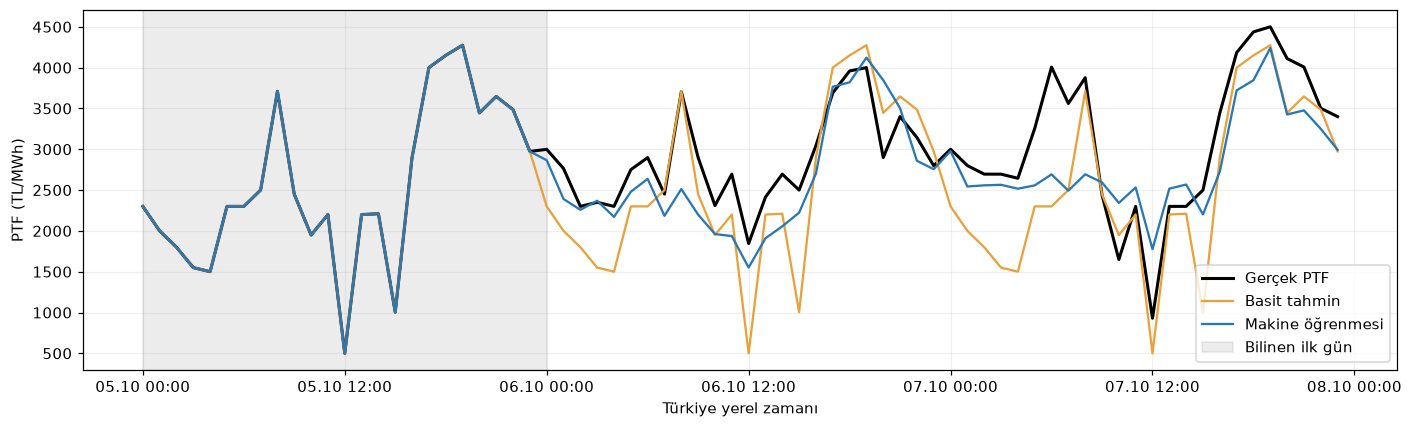

In [3]:
fig, ax = plt.subplots(figsize=(13, 4))
r = raporlar["tum_fiyatlar_biliniyor"]
ax.plot(r["tarih_saat"], r["gercek_fiyat"], color="black", linewidth=2, label="Gerçek PTF")
for yontem in ["basit_tahmin", "ml_tahmin"]:
    r = raporlar[yontem]
    ax.plot(r["tarih_saat"], r["kullanilan_fiyat"], label=etiketler[yontem], color={"basit_tahmin": "#e9a23b", "ml_tahmin": "#2878b5"}[yontem])
baslangic = gercek_firma["tesis_takvimi"]["tarih_saat"].min()
ax.axvspan(baslangic, baslangic + pd.Timedelta(hours=24), color="gray", alpha=0.15, label="Bilinen ilk gün")
ax.set_ylabel("PTF (TL/MWh)")
ax.set_xlabel("Türkiye yerel zamanı")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d.%m %H:%M"))
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 4. Gerçekleşmiş maliyet farkı

Avantaj, aynı referansın gerçekleşmiş maliyetinden önerinin gerçekleşmiş maliyetinin çıkarılmasıdır. Pozitif değer daha düşük maliyeti, negatif değer daha yüksek maliyeti gösterir. Beklenen maliyetteki iyileşme gerçek fiyatlarla kaybolabilir; negatif sonuçlar gizlenmez.

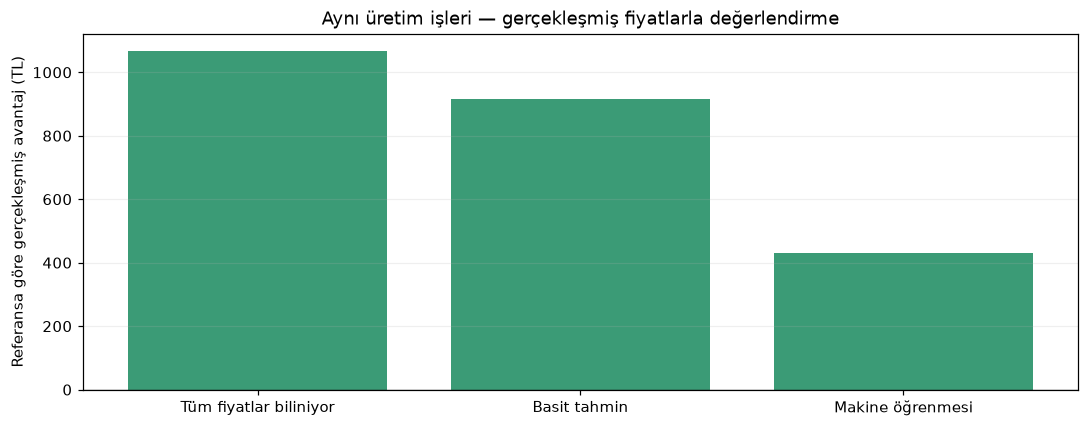

In [4]:
fig, ax = plt.subplots(figsize=(10, 4))
avantaj = karsilastirma["Gerçekleşmiş avantaj (TL)"]
ax.bar(karsilastirma["Yöntem"], avantaj,
       color=["#3b9b76" if d >= 0 else "#c85151" for d in avantaj])
ax.axhline(0, color="black", linewidth=0.8)
ax.set_ylabel("Referansa göre gerçekleşmiş avantaj (TL)")
ax.set_title("Aynı üretim işleri — gerçekleşmiş fiyatlarla değerlendirme")
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

## 5. Hata ve karar sonucu birlikte

Fiyat MAE'si ile maliyet farkı ayrı yorumlanır. Tahminler hangi saatlerin ucuz olduğunu farklı sıralayabilir; stok ve teslim kısıtları da her ucuz saatin kullanılmasına izin vermez. Çözücülerin süre sınırı ve kalan açıkları karşılaştırmanın bir parçasıdır.

In [5]:
basit = sonuclar["basit_tahmin"]
ml = sonuclar["ml_tahmin"]
print(f"Bu karar örneğinde basit MAE: {basit['fiyat_MAE_TL_MWh']:.2f} TL/MWh")
print(f"Bu karar örneğinde ML MAE: {ml['fiyat_MAE_TL_MWh']:.2f} TL/MWh")
print(f"Basit planın gerçekleşmiş maliyeti: {basit['gerceklesen_maliyet_tl']:,.2f} TL")
print(f"ML planının gerçekleşmiş maliyeti: {ml['gerceklesen_maliyet_tl']:,.2f} TL")
fark = basit["gerceklesen_maliyet_tl"] - ml["gerceklesen_maliyet_tl"]
print(f"ML planının basit plana göre maliyet farkı: {fark:,.2f} TL (pozitif: ML daha ucuz)")
if fark > 0.02:
    print("Bu örnekte ML ile bulunan plan, basit tahminle bulunan plandan daha düşük gerçekleşmiş maliyet verdi.")
elif fark < -0.02:
    print("Bu örnekte basit tahminle bulunan plan daha düşük gerçekleşmiş maliyet verdi; ML'nin karar üstünlüğü gösterilemedi.")
else:
    print("Bu örnekte gerçekleşmiş maliyetler aynı.")

Bu karar örneğinde basit MAE: 532.37 TL/MWh
Bu karar örneğinde ML MAE: 412.93 TL/MWh
Basit planın gerçekleşmiş maliyeti: 620,914.72 TL
ML planının gerçekleşmiş maliyeti: 621,400.50 TL
ML planının basit plana göre maliyet farkı: -485.78 TL (pozitif: ML daha ucuz)
Bu örnekte basit tahminle bulunan plan daha düşük gerçekleşmiş maliyet verdi; ML'nin karar üstünlüğü gösterilemedi.


Tek karar örneği bütün dönemlerde ekonomik üstünlük kanıtı değildir. Tüm fiyatların bilindiği kıyasın da matematiksel optimumu kanıtlanmadığından ona göre fark, kesin fırsat kaybı olarak adlandırılmaz. PTF ile tanımlı başlatma/geçiş giderleri değerlendirilir; bütün fabrika giderleri veya nihai fatura ölçülmüş değildir.

Yöntem: `docs/fiyat-tahmini-yontemi.md`. Hesaplama: `src/tahminli_cizelgeleme.py`. Kullanılmış girdiler, fiyatlar ve planlar: `data/results/tahminli_cizelgeleme`.